In [128]:
%load_ext autoreload
%autoreload 2
%reload_ext autoreload

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Reasoning System - Hetero GNN Encoder

***Imports***

In [96]:
# Python imports 
import random 
from collections import defaultdict
from itertools import islice
from pprint import pp

# PyTorch imports 
import torch 
from torch.utils.data import DataLoader

# HRI_GNN imports
from hri_gnn.config.const import Configuration, SLOT_TABLE, MAX_SLOTS
from hri_gnn.utils.paths import get_output_path
from hri_gnn.datasets import raven_flat_collate
from hri_gnn.datasets import RavenDataset
from hri_gnn.models.cnn_encoder import RavenCnnEncoder
from hri_gnn.models.gnn_encoder import RavenGnnEncoder, RavenGnnModel, CandidateScorer , score_and_loss_for_batch
from hri_gnn.models import graph_builder_v2 as gb
from hri_gnn.losses import compute_candidate_loss

***Load the Data***

In [111]:
torch.manual_seed(92)
random.seed(92)

PERCENTAGE_LIMIT = 0.1
BATCH_SIZE = 10
active_configs = [Configuration.IN_CENTER_SINGLE_OUT_CENTER_SINGLE.value]
train_dataset_raven_100 = RavenDataset(
    dataset='raven-100',
    split='train',
    percentage_limit=PERCENTAGE_LIMIT,
    configs=active_configs
)

train_dataloader = DataLoader(
    dataset=train_dataset_raven_100,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=raven_flat_collate
)


test_dataset_raven_100 = RavenDataset(
    dataset='raven-100',
    split='test',
    percentage_limit=PERCENTAGE_LIMIT,
    configs=active_configs
)

test_dataloader = DataLoader(
    dataset=test_dataset_raven_100,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=raven_flat_collate
)

val_dataset_raven_100 = RavenDataset(
    dataset='raven-100',
    split='val',
    percentage_limit=PERCENTAGE_LIMIT,
    configs=active_configs
)

val_dataloader = DataLoader(
    dataset=val_dataset_raven_100,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=raven_flat_collate
)


config : in_center_single_out_center_single
config : in_center_single_out_center_single
config : in_center_single_out_center_single


***Load the CNN Encoder Model***

In [4]:
# load the saved model 

output_path = get_output_path()

raven_encoder = RavenCnnEncoder()

raven_encoder.load_state_dict(torch.load(f=output_path/'models'/'raven_cnn_encoder_final.pth'))

<All keys matched successfully>

In [5]:
next(iter(raven_encoder.parameters())).device

device(type='cpu')

***what's in a batch ?..***

In [31]:
# grab the first batch 
batch = list(islice(val_dataloader, 0,1))[0]
print(f"The length of the batch: {len(batch)}")

The length of the batch: 9


In [46]:
count = 0
for tmp_batch in train_dataloader:
    count+= 1
    conf_prblm_batch = torch.stack([tmp_batch[5],tmp_batch[6], tmp_batch[7]]).unique(dim=-1)
    numb_prblm= conf_prblm_batch.shape[1]
    zipped = zip(conf_prblm_batch[0].tolist(), conf_prblm_batch[1].tolist(), conf_prblm_batch[2].tolist())
    problem_ids = [(i,j,k) for i,j,k in zipped] 
    print(f"batch number: {count}, problems count: {numb_prblm}, (cnfg_id, prblm_id, btc_id): {problem_ids}")

print(f"dataset length: {len(val_dataset_raven_100)}")
print(f"dataloader length: {count}")

batch number: 1, problems count: 21, (cnfg_id, prblm_id, btc_id): [(0, 63, 8), (0, 80, 10), (1, 3, 12), (2, 31, 15), (3, 5, 14), (4, 10, 9), (4, 42, 14), (4, 45, 12), (4, 65, 11), (4, 73, 10), (4, 81, 15), (4, 83, 9), (4, 85, 15), (5, 10, 10), (5, 65, 9), (5, 72, 11), (6, 51, 15), (6, 73, 11), (6, 82, 13), (6, 83, 15), (6, 90, 11)]
dataset length: 7
dataloader length: 1


In [8]:
flat_crops                = batch[0] # crops               ,shape: [xxx, 1, 80, 80]
flat_attributes           = batch[1] # attributes          ,shape: [xxx, 4]
flat_bboxes               = batch[2] # bbox                ,shape: [xxx, 4] 
flat_panel_indices        = batch[3] # panel indices       ,shape: [xxx]
flat_component_indices    = batch[4] # component indices   ,shape: [xxx]
flat_config_indices       = batch[5] # config indices      ,shape: [xxx]
flat_problem_indices      = batch[6] # problems indices    ,shape: [xxx]
flat_problem_targets      = batch[7] # problems targets    ,shape: [xxx]
flat_batch_indices        = batch[8] # batch indices       ,shape: [xxx]

***Encode batch's entities (crops) `CNN Encoder - Forward pass`***

In [9]:
raven_encoder.eval()
with torch.inference_mode():
    model_output = raven_encoder(flat_crops)

pp(f"Model output dictionnary keys: {model_output.keys()}")

("Model output dictionnary keys: dict_keys(['latent_vector', "
 "'pred_type_logits', 'pred_size_logits', 'pred_color_logits', "
 "'pred_angle_logits'])")


***build_hetero_data_batch***

In [10]:
from hri_gnn.config.const import Configuration
hetero_data_dict, meta_dict = gb.build_hetero_data_batch(batch, raven_encoder, include_columns= True, candidate_ids=range(8,16), device= None)

print(f"number of problems: {len(hetero_data_dict)}")
problem_key =  (4, 46, 8)  #(0, 7, 9)
problem_hetero_data = hetero_data_dict[problem_key]
problem_metadata = meta_dict[problem_key]
print("Exemple (first problem):\n")
print(f" - problem key: {problem_key}, CONFIG: {Configuration.all()[problem_key[0]]}")
print(f" - problem data:")
print(f"    - Type: {type(problem_hetero_data)}")
print(f"    - target: {problem_hetero_data['y']}")
print(f"    - Metadata: ")
print(f"       - nodes_count:")
for node_type, node_count in problem_metadata['nodes_counts'].items():
    print(f"               - {node_type}: {node_count} , \tx dimension: {problem_hetero_data[node_type].x.shape[1]}")
print(f"       - edges_count:")
for edge_type, edge_count in problem_metadata['edges_counts'].items():
    print(f"               - {edge_type}: {edge_count} , \tattr dimension: {problem_hetero_data[edge_type].edge_attr.shape[1]}")
print(f"       - layout_keys:")

print(f"       - entity_meta:")
for k, v in problem_metadata['entity_meta'].items():
    print(f"               - {k}: {v}")




number of problems: 10
Exemple (first problem):

 - problem key: (4, 46, 8), CONFIG: in_distribute_four_out_center_single
 - problem data:
    - Type: <class 'torch_geometric.data.hetero_data.HeteroData'>
    - target: tensor([14])
    - Metadata: 
       - nodes_count:
               - entity: 57 , 	x dimension: 86
               - layout: 32 , 	x dimension: 97
       - edges_count:
               - ('entity', 'intra_panel', 'entity'): 78 , 	attr dimension: 2
               - ('entity', 'inter_panel_entity', 'entity'): 246 , 	attr dimension: 23
               - ('layout', 'inter_panel_layout', 'layout'): 184 , 	attr dimension: 5
               - ('entity', 'belongs_to', 'layout'): 57 , 	attr dimension: 1
               - ('layout', 'contains', 'entity'): 57 , 	attr dimension: 1
       - layout_keys:
       - entity_meta:
               - panel_id: tensor([ 0,  0,  1,  1,  1,  2,  2,  2,  2,  3,  3,  3,  3,  4,  4,  4,  5,  5,
         5,  5,  5,  6,  6,  6,  7,  7,  8,  8,  8,  8,  8,

***RavenGnnEncoder***

***Test 1 : Option A (only edges with homogeneous nodes)***

In [11]:
homogeneous_edges = [
    ('entity', 'intra_panel', 'entity'),
    ('entity', 'inter_panel_entity', 'entity'),
    ('layout', 'inter_panel_layout', 'layout')
]

in_dims = {'entity': problem_hetero_data['entity'].x.shape[1] , 'layout': problem_hetero_data['layout'].x.shape[1]}

gnn_a = RavenGnnEncoder(in_dims, hidden_dim=64, num_layers=3, active_edge_types=homogeneous_edges)

x_dict = {'entity': problem_hetero_data['entity'].x , 'layout': problem_hetero_data['layout'].x}
edge_index_dict = {edge_type : problem_hetero_data[edge_type].edge_index for edge_type in homogeneous_edges}
edge_attr_dict = {edge_type : problem_hetero_data[edge_type].edge_attr for edge_type in homogeneous_edges}

out_a  = gnn_a(x_dict, edge_index_dict, edge_attr_dict)

print(f"Gnn Encoder output:\n")
print(f"Entity representations:\n{out_a['entity']} , with shape {out_a['entity'].shape}")
print(f"Layout representations:\n{out_a['layout']} , with shape {out_a['layout'].shape}")

Gnn Encoder output:

Entity representations:
tensor([[ -1.1347,  21.8316,   2.8346,  ..., -17.9989,  -1.3458, -14.4177],
        [ -2.8238,   4.2588,   1.6978,  ..., -16.5977,  -2.2464, -11.9619],
        [ -1.0292,  20.8897,   2.7216,  ..., -20.8464,  -1.3506, -14.4449],
        ...,
        [  9.0992,  14.2501,   3.4802,  ..., -32.5252,   1.3451, -32.9378],
        [  8.1964,   8.9966,   1.7482,  ..., -12.5806,  -0.2746, -20.7845],
        [  7.3537,  11.2893,   2.5001,  ..., -31.4031,   2.5980, -27.8738]],
       grad_fn=<SumBackward1>) , with shape torch.Size([57, 64])
Layout representations:
tensor([[  6.0645, -15.4177,  55.7435,  ...,  17.6197,  34.1953,  10.1844],
        [  8.4674, -10.3893,  61.5634,  ...,  16.4333,  35.5838,   9.1594],
        [  5.9140, -15.2383,  55.5720,  ...,  17.6264,  34.1565,  10.2374],
        ...,
        [  9.7961, -12.8255,  80.6495,  ...,  21.8092,  46.7393,  13.4165],
        [  8.1068, -19.5325,  71.2770,  ...,  23.2310,  43.8369,  12.9188],
   

***Test 2 : Option B (only edges inter panels)***

In [12]:
inter_panels_edges = [
    ('entity', 'inter_panel_entity', 'entity'),
    ('layout', 'inter_panel_layout', 'layout')
]

in_dims = {'entity': problem_hetero_data['entity'].x.shape[1] , 'layout': problem_hetero_data['layout'].x.shape[1]}

gnn_b = RavenGnnEncoder(in_dims, hidden_dim=64, num_layers=3, active_edge_types=inter_panels_edges)

x_dict = {'entity': problem_hetero_data['entity'].x , 'layout': problem_hetero_data['layout'].x}
edge_index_dict = {edge_type : problem_hetero_data[edge_type].edge_index for edge_type in inter_panels_edges}
edge_attr_dict = {edge_type : problem_hetero_data[edge_type].edge_attr for edge_type in inter_panels_edges}

out_b  = gnn_b(x_dict, edge_index_dict, edge_attr_dict)

print(f"Gnn Encoder output:\n")
print(f"Entity representations:\n{out_b['entity']} , with shape {out_b['entity'].shape}")
print(f"Layout representations:\n{out_b['layout']} , with shape {out_b['layout'].shape}")

Gnn Encoder output:

Entity representations:
tensor([[  4.4136,  18.4994, -15.0780,  ...,  26.3581,  -1.7198, -12.8214],
        [ -0.8739,   7.2761, -13.8271,  ...,  12.0435,   5.3524,  -9.3789],
        [  5.0719,  21.5409, -14.9817,  ...,  23.0550,  -5.3540, -11.1181],
        ...,
        [  5.8896,   8.5446, -24.7482,  ...,  18.9862,   2.6625,  -7.5390],
        [  7.0274,   4.5824, -11.8843,  ...,   8.5982,   1.3027,  -2.9935],
        [  1.6229,   8.2345, -20.3247,  ...,  12.7677,   2.7960,  -6.4438]],
       grad_fn=<AddmmBackward0>) , with shape torch.Size([57, 64])
Layout representations:
tensor([[ 3.4650e+01, -6.9565e-02, -1.7774e+00,  ..., -2.9042e+01,
          1.3993e+01, -2.8432e+01],
        [ 3.8696e+01, -2.9552e+00, -9.8004e+00,  ..., -4.6148e+01,
          9.4452e+00, -3.4577e+01],
        [ 3.4253e+01, -1.9546e-02, -1.8282e+00,  ..., -2.9083e+01,
          1.3994e+01, -2.8684e+01],
        ...,
        [ 4.9916e+01, -4.8299e+00, -1.2290e+01,  ..., -5.9505e+01,
     

***Test 3 : Option C (only edges with layout nodes)***

In [13]:
layout_laout_edges = [
    ('layout', 'inter_panel_layout', 'layout')
]

in_dims = {'layout': problem_hetero_data['layout'].x.shape[1]}

gnn_c = RavenGnnEncoder(in_dims, hidden_dim=64, num_layers=3, active_edge_types=layout_laout_edges)

x_dict = {'layout': problem_hetero_data['layout'].x}
edge_index_dict = {edge_type : problem_hetero_data[edge_type].edge_index for edge_type in layout_laout_edges}
edge_attr_dict = {edge_type : problem_hetero_data[edge_type].edge_attr for edge_type in layout_laout_edges}

out_c  = gnn_c(x_dict, edge_index_dict, edge_attr_dict)

print(f"Gnn Encoder output:\n")
print(f"Layout representations:\n{out_c['layout']} , with shape {out_c['layout'].shape}")

Gnn Encoder output:

Layout representations:
tensor([[ -3.9443,  25.8282, -20.1503,  ...,  20.2867,  21.5934, -11.6001],
        [ -6.8372,  19.7228,  -7.6661,  ...,  13.4670,  24.8001,   0.9168],
        [ -4.3888,  26.0010, -20.4186,  ...,  20.6690,  21.5991, -11.5899],
        ...,
        [ -7.3737,  27.5363, -11.1666,  ...,  19.7307,  32.7481,   0.8641],
        [ -5.5161,  33.9999, -27.7807,  ...,  27.8016,  27.5018, -16.2243],
        [ -7.3728,  27.5401, -11.1727,  ...,  19.7369,  32.7527,   0.8652]],
       grad_fn=<AddmmBackward0>) , with shape torch.Size([32, 64])


***CandidateScorer***

In [14]:

scorer = CandidateScorer(hidden_dim=64)
scores_tensor, scores_dict =  scorer(out_c['layout'], problem_metadata['layout_keys'], range(8,16), return_dict=True)

print(f"Scores tensor:\n{scores_tensor}")
print(f"Scores dictionnary:\n{scores_dict}")

print(f"Target index :\t{problem_hetero_data['y']}")

# prediction probabilities 
probabilities = scores_tensor.softmax(dim=0)
print(f"probabilities tensor:\n{probabilities}")

# prediction 
prediction = probabilities.argmax()+8
print(f"Prediction:\n{prediction}")

Scores tensor:
tensor([-4.8431, -4.8455, -4.8710, -4.8599, -4.8590, -4.8234, -4.8541, -4.8440],
       grad_fn=<CatBackward0>)
Scores dictionnary:
{8: -4.8431396484375, 9: -4.845544815063477, 10: -4.871047496795654, 11: -4.85986328125, 12: -4.859010219573975, 13: -4.823404312133789, 14: -4.854050636291504, 15: -4.843972206115723}
Target index :	tensor([14])
probabilities tensor:
tensor([0.1258, 0.1255, 0.1224, 0.1238, 0.1239, 0.1284, 0.1245, 0.1257],
       grad_fn=<SoftmaxBackward0>)
Prediction:
13


***compute_candidate_loss***

In [15]:
loss = compute_candidate_loss(scores_tensor, problem_hetero_data['y'], range(8,16))

print(f"Loss: {loss}")

Loss: 2.0835788249969482


***build_pyg_batch***

In [16]:
pyg_batch, batched_layout_keys, keys_order = gb.build_pyg_batch(hetero_data_dict, meta_dict)

print(f"Batch problem keys :\n{keys_order}")
print(f"Batch layout keys (panel_id, component_id):\n {batched_layout_keys}")
print(f"HeteroDataBatch keys: {pyg_batch.keys()}")


Batch problem keys :
[(5, 47, 0), (6, 6, 1), (3, 56, 2), (1, 36, 3), (6, 76, 4), (6, 16, 5), (2, 16, 6), (0, 97, 7), (4, 46, 8), (0, 7, 9)]
Batch layout keys (panel_id, component_id):
 [(0, 0), (0, 1), (1, 0), (1, 1), (2, 0), (2, 1), (3, 0), (3, 1), (4, 0), (4, 1), (5, 0), (5, 1), (6, 0), (6, 1), (7, 0), (7, 1), (8, 0), (8, 1), (9, 0), (9, 1), (10, 0), (10, 1), (11, 0), (11, 1), (12, 0), (12, 1), (13, 0), (13, 1), (14, 0), (14, 1), (15, 0), (15, 1), (0, 0), (0, 1), (1, 0), (1, 1), (2, 0), (2, 1), (3, 0), (3, 1), (4, 0), (4, 1), (5, 0), (5, 1), (6, 0), (6, 1), (7, 0), (7, 1), (8, 0), (8, 1), (9, 0), (9, 1), (10, 0), (10, 1), (11, 0), (11, 1), (12, 0), (12, 1), (13, 0), (13, 1), (14, 0), (14, 1), (15, 0), (15, 1), (0, 0), (0, 1), (1, 0), (1, 1), (2, 0), (2, 1), (3, 0), (3, 1), (4, 0), (4, 1), (5, 0), (5, 1), (6, 0), (6, 1), (7, 0), (7, 1), (8, 0), (8, 1), (9, 0), (9, 1), (10, 0), (10, 1), (11, 0), (11, 1), (12, 0), (12, 1), (13, 0), (13, 1), (14, 0), (14, 1), (15, 0), (15, 1), (0, 0), (1

***Messaging Passing***

In [22]:
# Active edges 
layout_layout_edges = [
    ('layout', 'inter_panel_layout', 'layout'),
    ('entity','inter_panel_entity','entity')
]

# Input nodes dimenstion , here we use unified batch vector `batch['node_type'].x` (concatenation of all the problems in the batch)
in_dims = {'entity': pyg_batch['entity'].x.shape[1] , 'layout': pyg_batch['layout'].x.shape[1]}

# instantiation of the GNN encoder, with  iput the batch vector `batch['node_type'].x` dimension, hidden dimension 64,  3 layers and only layout <-> layout active edges
gnn = RavenGnnEncoder(in_dims, hidden_dim=64, num_layers=3, active_edge_types=layout_layout_edges)

# The actual repspresentaion of the nodes  (we use the batch vector `batch['node_type'].x` and for this example only the layout nodes)
x_dict = {'entity': pyg_batch['entity'].x , 'layout': pyg_batch['layout'].x}

# Edges dictionnaries (indexes and attributes) (we use the batch vector `batch[('egde_type')].edge_index` & `batch[('egde_type')].edge_attr` and for this specific example only layout <-> layout edges, see active_edge_types above)
edge_index_dict = {edge_type : pyg_batch[edge_type].edge_index for edge_type in layout_layout_edges}
edge_attr_dict = {edge_type : pyg_batch[edge_type].edge_attr for edge_type in layout_layout_edges}

# Forward 'MESSAGE PASSING' + Updating representation `batch['node_type'].x` (nodes attr only but using edges attr, see `GINEConv`)
gnn_out = gnn(x_dict, edge_index_dict, edge_attr_dict)

print(f"Gnn Encoder output:\n")
print(f"Layout representations:\n{gnn_out['layout']} , with shape {gnn_out['layout'].shape}")
print(f"Batch vector , Layout representations:\n{pyg_batch['layout'].batch} , with shape {pyg_batch['layout'].batch.shape}")

# The new respresentaion of all layout nodes in the batch (the new `batch['node_type'].x`)
h_layout = gnn_out['layout']

# position of the node in the batch (multiple nodes can share same position)
# Example : 
#     batch = 10 HeteroData, each HeteroData have its own number of node
#     (first HeteroData, 4 nodes) ,(2nd HeteroData, 6 nodes).... 
#     => `batch[node_type]`  0,0,0,0,1,1,1,1,1,1,2,2,2,2,2....
layout_batch_vector = pyg_batch['layout'].batch

# batch's problems targets 
y_batch = pyg_batch.y

# Number of problems in the batch
n_problems = len(keys_order)

Gnn Encoder output:

Layout representations:
tensor([[-32.8518,  14.9728,  17.9668,  ..., -13.5404, -11.1540, -13.7883],
        [-37.6119,  16.9576,  19.3660,  ..., -11.0890, -13.6467, -14.0587],
        [-33.2040,  14.8090,  17.9063,  ..., -13.2278, -10.7720, -14.1430],
        ...,
        [-46.7159,  25.7443,  49.4625,  ..., -36.5079, -11.1870, -50.8500],
        [-46.5175,  25.5629,  49.3227,  ..., -36.3825, -11.2426, -50.5623],
        [-46.6447,  25.6753,  49.4159,  ..., -36.4491, -11.1823, -50.5897]],
       grad_fn=<AddmmBackward0>) , with shape torch.Size([256, 64])
Batch vector , Layout representations:
tensor([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2,
        2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
        3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 4,

***score_and_loss_for_batch***

In [18]:
scores_per_problem, losses_per_problem, mean_loss = score_and_loss_for_batch(h_layout, layout_batch_vector, batched_layout_keys, y_batch, scorer, range(8,16), n_problems)
scores_per_problem, losses_per_problem, mean_loss

([tensor([-6.1928, -6.1930, -6.1945, -6.1925, -6.2011, -6.1928, -6.1927, -6.2033],
         grad_fn=<CatBackward0>),
  tensor([-5.7486, -5.7553, -5.7486, -5.7731, -5.7362, -5.7442, -5.7458, -5.7486],
         grad_fn=<CatBackward0>),
  tensor([-4.4797, -4.4871, -4.4869, -4.4739, -4.4873, -4.4807, -4.4926, -4.4877],
         grad_fn=<CatBackward0>),
  tensor([-6.5838, -6.6224, -6.6887, -6.6228, -6.6048, -6.5870, -6.6196, -6.6125],
         grad_fn=<CatBackward0>),
  tensor([-7.3390, -7.3201, -7.3390, -7.3390, -7.3477, -7.3390, -7.3430, -7.3159],
         grad_fn=<CatBackward0>),
  tensor([-8.6680, -8.6513, -8.6680, -8.6661, -8.6440, -8.6680, -8.6680, -8.6680],
         grad_fn=<CatBackward0>),
  tensor([-5.6923, -5.6921, -5.7267, -5.7251, -5.7236, -5.7594, -5.6978, -5.6216],
         grad_fn=<CatBackward0>),
  tensor([-4.0719, -4.0905, -4.0759, -4.0856, -4.0742, -4.0804, -4.0751, -4.0864],
         grad_fn=<CatBackward0>),
  tensor([-4.3493, -4.2929, -4.2981, -4.3054, -4.2946, -4.2944, 

***RavenGnnModel***

In [23]:
# in_dims = {'layout': pyg_batch['layout'].x.shape[1]}

raven_gnn_model = RavenGnnModel(in_dims=in_dims, hidden_dim=64, num_layers=3) # since active_edge_types = None -> all edge type are activated

scores_per_problem, losses_per_problem, mean_loss = raven_gnn_model(pyg_batch, batched_layout_keys, n_problems)

scores_per_problem, losses_per_problem, mean_loss

([tensor([-3.4539, -3.9598, -3.7368, -3.5318, -3.7378, -3.7384, -3.4754, -3.7398],
         grad_fn=<CatBackward0>),
  tensor([-4.0983, -3.8774, -3.8774, -3.8777, -3.8766, -3.8772, -3.8764, -4.2520],
         grad_fn=<CatBackward0>),
  tensor([-2.8146, -2.5672, -2.5673, -2.7914, -2.5673, -2.2137, -2.6065, -2.2595],
         grad_fn=<CatBackward0>),
  tensor([-2.9301, -2.9334, -1.6213, -2.8653, -2.8978, -2.9279, -2.8398, -2.8969],
         grad_fn=<CatBackward0>),
  tensor([-4.0019, -4.8191, -4.0011, -4.0041, -3.9298, -4.0012, -4.3109, -3.9916],
         grad_fn=<CatBackward0>),
  tensor([-3.5357, -3.2243, -3.5357, -4.0235, -3.2923, -3.5357, -3.5357, -3.5357],
         grad_fn=<CatBackward0>),
  tensor([ 4.0217,  4.0383,  2.6520,  2.6573,  2.6414,  5.1983,  3.7189, -2.8907],
         grad_fn=<CatBackward0>),
  tensor([-2.3436, -2.3530, -2.3536, -2.3141, -2.2932, -2.3486, -2.2899, -2.5843],
         grad_fn=<CatBackward0>),
  tensor([-7.5116, -2.5976, -3.9084, -5.9616, -3.0964, -5.1673, 

In [1]:
%load_ext autoreload
%autoreload 2
%reload_ext autoreload

In [2]:
# Python imports 
import random 
from collections import defaultdict
from itertools import islice
from pprint import pp
import json

# PyTorch imports 
import torch
import torch.nn as nn 
from torch.utils.data import DataLoader

# matplotlib imports
import matplotlib.pyplot as plt 

# HRI_GNN imports
from hri_gnn.config.const import Configuration, SLOT_TABLE, MAX_SLOTS, GRAPH_NODE_TYPES, GRAPH_EDGE_TYPES
from hri_gnn.utils import paths
from hri_gnn.datasets import raven_flat_collate
from hri_gnn.datasets import RavenDataset
from hri_gnn.models.cnn_encoder import RavenCnnEncoder
from hri_gnn.models.gnn_encoder import RavenGnnEncoder, RavenGnnModel, CandidateScorer , score_and_loss_for_batch
from hri_gnn.models import graph_builder_v2 as gb
from hri_gnn.losses import compute_candidate_loss
from hri_gnn.training.gnn_trainer import GnnTrainer

In [3]:
# load the saved model 

output_path = paths.get_output_path()

raven_encoder = RavenCnnEncoder()

raven_encoder.load_state_dict(torch.load(f=output_path/'models'/'raven_cnn_encoder_final.pth'))

<All keys matched successfully>

In [4]:
from hri_gnn.config.const import SPLITS
torch.manual_seed(92)
random.seed(92)

DATASET = 'raven-20000'
PERCENTAGE_LIMIT = 0.05
BATCH_SIZE = 50

active_configs = [Configuration.CENTER_SINGLE.value]

datatsets_dict = {}
dataloaders_dict = {}

for config in Configuration.all():
    for split in SPLITS:
        datatsets_dict[f"{config}_{split}"] = RavenDataset(dataset=DATASET,
                                              split=split,
                                              percentage_limit=PERCENTAGE_LIMIT,
                                              configs=[config])
        dataloaders_dict[f"{config}_{split}"] = DataLoader(
                                                dataset=datatsets_dict[f"{config}_{split}"],
                                                batch_size=BATCH_SIZE,
                                                shuffle= split == 'train',
                                                collate_fn=raven_flat_collate)

In [5]:
for config in Configuration.all():
    print("="*60)
    for split in SPLITS:
        print(f"{config}_{split}: \t\t {len(datatsets_dict[f"{config}_{split}"])}")

center_single_train: 		 470
center_single_test: 		 157
center_single_val: 		 157
distribute_four_train: 		 600
distribute_four_test: 		 200
distribute_four_val: 		 200
distribute_nine_train: 		 600
distribute_nine_test: 		 200
distribute_nine_val: 		 200
in_center_single_out_center_single_train: 		 600
in_center_single_out_center_single_test: 		 200
in_center_single_out_center_single_val: 		 200
in_distribute_four_out_center_single_train: 		 600
in_distribute_four_out_center_single_test: 		 200
in_distribute_four_out_center_single_val: 		 200
left_center_single_right_center_single_train: 		 600
left_center_single_right_center_single_test: 		 200
left_center_single_right_center_single_val: 		 200
up_center_single_down_center_single_train: 		 600
up_center_single_down_center_single_test: 		 200
up_center_single_down_center_single_val: 		 200


***GnnTrainer***

In [6]:
output_path = paths.get_output_path()
paths.output_paths(output_path)

gnn_model = RavenGnnModel(GRAPH_NODE_TYPES, hidden_dim=32, num_layers=3).to("cuda")
optimizer = torch.optim.Adam(gnn_model.parameters(), lr=1e-3)

# homogeniuos edges
option_A = [ ('entity', 'intra_panel', 'entity'),('entity', 'inter_panel_entity', 'entity'),('layout', 'inter_panel_layout', 'layout')]
# layout edges only
option_B = [ ('layout', 'inter_panel_layout', 'layout')]
# inter panels only 
option_C = [ ('entity', 'inter_panel_entity', 'entity'), ('layout', 'inter_panel_layout', 'layout')]
# entity edges only
option_D = [ ('entity', 'intra_panel', 'entity'),('entity', 'inter_panel_entity', 'entity')]

train_only = False
active_edge_types = None # all edges are activated
include_columns = True 
epochs = 20

history_dict = {}
for config in Configuration.all():
    print(f"Training {config}....")

    # 1. Instantiate the GNN model (fresh instace for each config)
    gnn_trainer = GnnTrainer(gnn_model, raven_encoder, optimizer, metrics=None, node_types= None, 
                             active_edge_types= active_edge_types, 
                             include_columns=include_columns, device="cuda", output_path= output_path)
    # 2. Train the GNN model
    history_dict[config] = gnn_trainer.fit(dataloaders_dict[f"{config}_train"] , 
                                           dataloaders_dict[f"{config}_test"], 
                                           epochs=epochs, 
                                           max_grad_norm=1.0, 
                                           checkpoint_name_prefix = config,
                                           check_frequency=5,
                                           save_final_version= True,
                                           verbose=False, 
                                           train_only= train_only)
    # 3. Saving the training history
    history_path = output_path/"history"/"gnn"/f"training_history_{config}.json"
    with open(history_path, 'w') as f:
        json.dump(history_dict[config], f, indent=2)
    print(f"\n[OK] Training history {config} saved : {history_path}")

    print("="*80)

Training center_single....


  0%|          | 0/20 [00:00<?, ?it/s]

 > Saved checkpoint: C:\Users\dhias\workspaces\these\HRI-GNN\outputs\checkpoints\gnn\gnn_model_center_single_checkpoint_epoch_5.pth
 > Saved checkpoint: C:\Users\dhias\workspaces\these\HRI-GNN\outputs\checkpoints\gnn\gnn_model_center_single_checkpoint_epoch_10.pth
 > Saved checkpoint: C:\Users\dhias\workspaces\these\HRI-GNN\outputs\checkpoints\gnn\gnn_model_center_single_checkpoint_epoch_15.pth
 > Saved checkpoint: C:\Users\dhias\workspaces\these\HRI-GNN\outputs\checkpoints\gnn\gnn_model_center_single_checkpoint_epoch_20.pth
 > Saved final model: C:\Users\dhias\workspaces\these\HRI-GNN\outputs\models\ gnn_model_center_single_final.pth

Training finished!....
- Train (Test) number of problems: [470] ([157])
- Train (Test) number of nodes per node type: {'entity': [7520], 'layout': [7520]} ({'entity': [2512], 'layout': [2512]})
- Train (Test) number of edges per edge type: {('entity', 'intra_panel', 'entity'): [0], ('entity', 'inter_panel_entity', 'entity'): [43240], ('layout', 'inter_pa

  0%|          | 0/20 [00:00<?, ?it/s]

 > Saved checkpoint: C:\Users\dhias\workspaces\these\HRI-GNN\outputs\checkpoints\gnn\gnn_model_distribute_four_checkpoint_epoch_5.pth
 > Saved checkpoint: C:\Users\dhias\workspaces\these\HRI-GNN\outputs\checkpoints\gnn\gnn_model_distribute_four_checkpoint_epoch_10.pth
 > Saved checkpoint: C:\Users\dhias\workspaces\these\HRI-GNN\outputs\checkpoints\gnn\gnn_model_distribute_four_checkpoint_epoch_15.pth
 > Saved checkpoint: C:\Users\dhias\workspaces\these\HRI-GNN\outputs\checkpoints\gnn\gnn_model_distribute_four_checkpoint_epoch_20.pth
 > Saved final model: C:\Users\dhias\workspaces\these\HRI-GNN\outputs\models\ gnn_model_distribute_four_final.pth

Training finished!....
- Train (Test) number of problems: [600] ([200])
- Train (Test) number of nodes per node type: {'entity': [21773], 'layout': [9600]} ({'entity': [7232], 'layout': [3200]})
- Train (Test) number of edges per edge type: {('entity', 'intra_panel', 'entity'): [38212], ('entity', 'inter_panel_entity', 'entity'): [74618], ('lay

  0%|          | 0/20 [00:00<?, ?it/s]

... (5 outputs left out)

  0%|          | 0/20 [00:00<?, ?it/s]

 > Saved checkpoint: C:\Users\dhias\workspaces\these\HRI-GNN\outputs\checkpoints\gnn\gnn_model_left_center_single_right_center_single_checkpoint_epoch_5.pth
 > Saved checkpoint: C:\Users\dhias\workspaces\these\HRI-GNN\outputs\checkpoints\gnn\gnn_model_left_center_single_right_center_single_checkpoint_epoch_10.pth
 > Saved checkpoint: C:\Users\dhias\workspaces\these\HRI-GNN\outputs\checkpoints\gnn\gnn_model_left_center_single_right_center_single_checkpoint_epoch_15.pth
 > Saved checkpoint: C:\Users\dhias\workspaces\these\HRI-GNN\outputs\checkpoints\gnn\gnn_model_left_center_single_right_center_single_checkpoint_epoch_20.pth
 > Saved final model: C:\Users\dhias\workspaces\these\HRI-GNN\outputs\models\ gnn_model_left_center_single_right_center_single_final.pth

Training finished!....
- Train (Test) number of problems: [600] ([200])
- Train (Test) number of nodes per node type: {'entity': [19200], 'layout': [19200]} ({'entity': [6400], 'layout': [6400]})
- Train (Test) number of edges per 

  0%|          | 0/20 [00:00<?, ?it/s]

 > Saved checkpoint: C:\Users\dhias\workspaces\these\HRI-GNN\outputs\checkpoints\gnn\gnn_model_up_center_single_down_center_single_checkpoint_epoch_5.pth
 > Saved checkpoint: C:\Users\dhias\workspaces\these\HRI-GNN\outputs\checkpoints\gnn\gnn_model_up_center_single_down_center_single_checkpoint_epoch_10.pth
 > Saved checkpoint: C:\Users\dhias\workspaces\these\HRI-GNN\outputs\checkpoints\gnn\gnn_model_up_center_single_down_center_single_checkpoint_epoch_15.pth
 > Saved checkpoint: C:\Users\dhias\workspaces\these\HRI-GNN\outputs\checkpoints\gnn\gnn_model_up_center_single_down_center_single_checkpoint_epoch_20.pth
 > Saved final model: C:\Users\dhias\workspaces\these\HRI-GNN\outputs\models\ gnn_model_up_center_single_down_center_single_final.pth

Training finished!....
- Train (Test) number of problems: [600] ([200])
- Train (Test) number of nodes per node type: {'entity': [19200], 'layout': [19200]} ({'entity': [6400], 'layout': [6400]})
- Train (Test) number of edges per edge type: {('e


[OK] center_single curves saved to C:\Users\dhias\workspaces\these\HRI-GNN\outputs\metric_curves\gnn\center_single_loss_accuracy.png

[OK] distribute_four curves saved to C:\Users\dhias\workspaces\these\HRI-GNN\outputs\metric_curves\gnn\distribute_four_loss_accuracy.png

[OK] distribute_nine curves saved to C:\Users\dhias\workspaces\these\HRI-GNN\outputs\metric_curves\gnn\distribute_nine_loss_accuracy.png

[OK] in_center_single_out_center_single curves saved to C:\Users\dhias\workspaces\these\HRI-GNN\outputs\metric_curves\gnn\in_center_single_out_center_single_loss_accuracy.png

[OK] in_distribute_four_out_center_single curves saved to C:\Users\dhias\workspaces\these\HRI-GNN\outputs\metric_curves\gnn\in_distribute_four_out_center_single_loss_accuracy.png

[OK] left_center_single_right_center_single curves saved to C:\Users\dhias\workspaces\these\HRI-GNN\outputs\metric_curves\gnn\left_center_single_right_center_single_loss_accuracy.png

[OK] up_center_single_down_center_single curves s

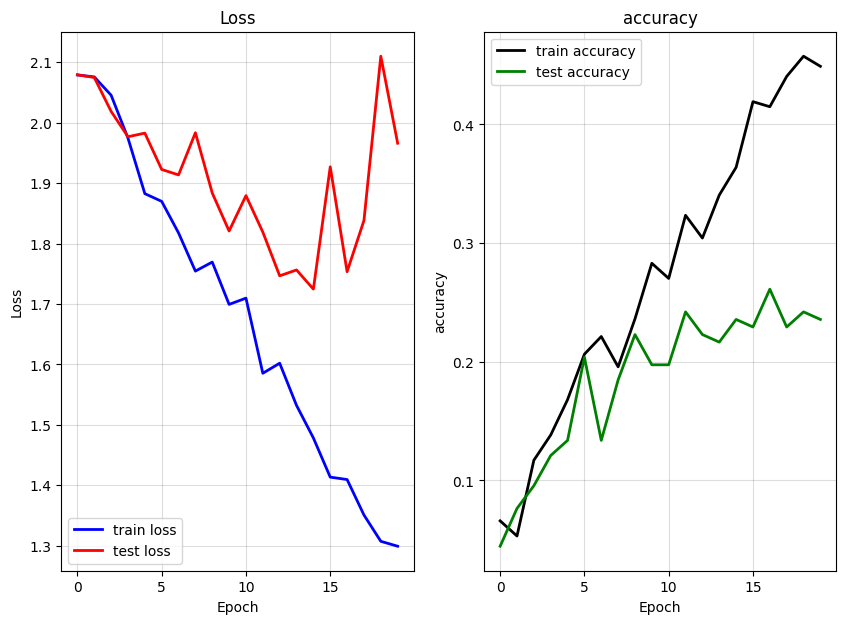

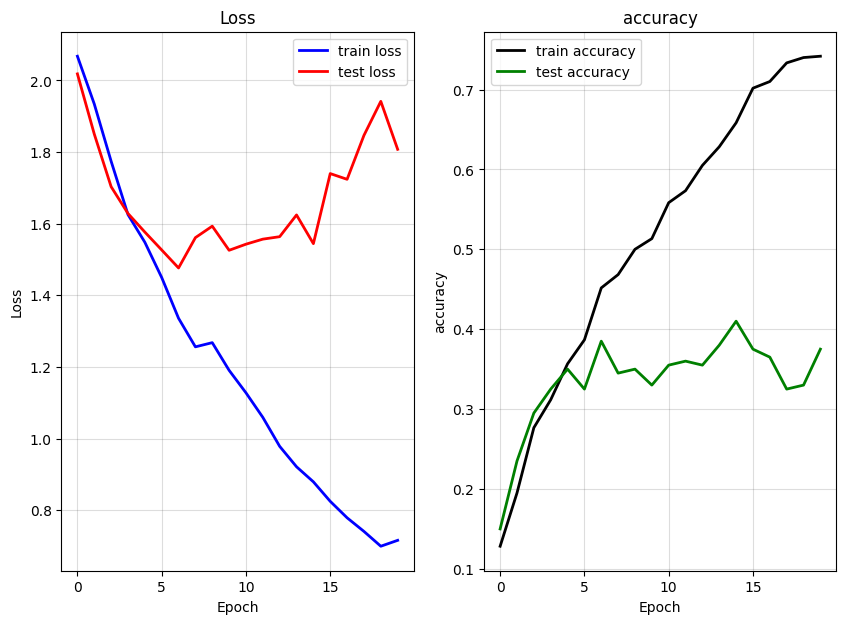

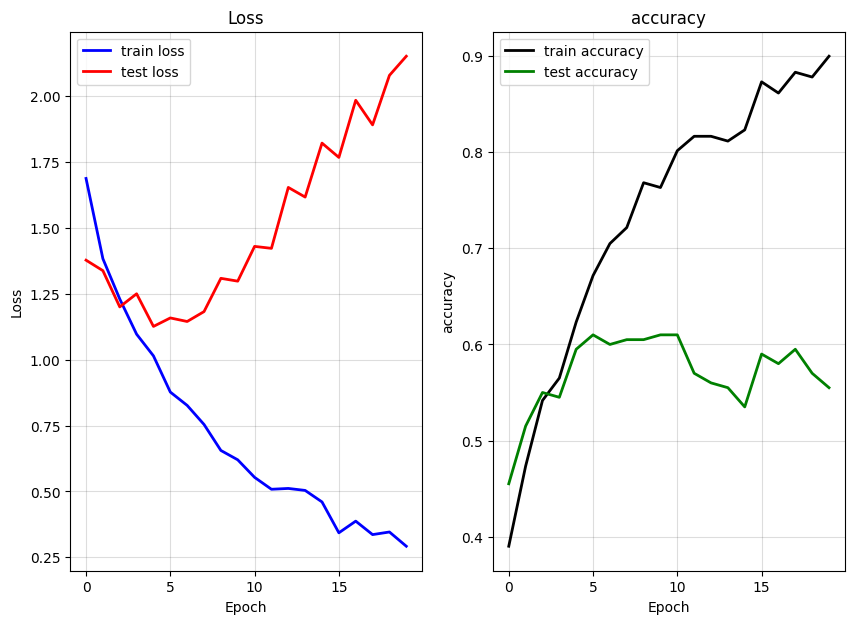

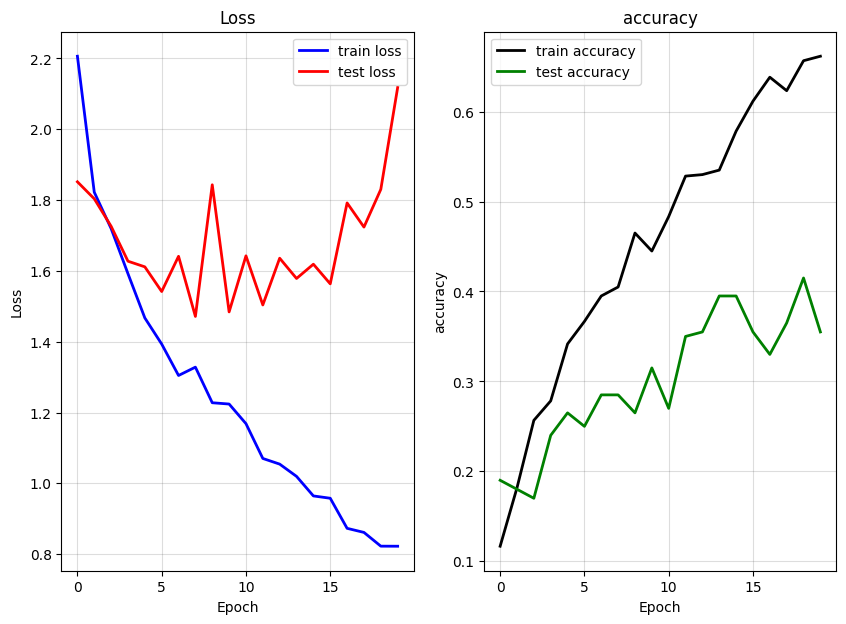

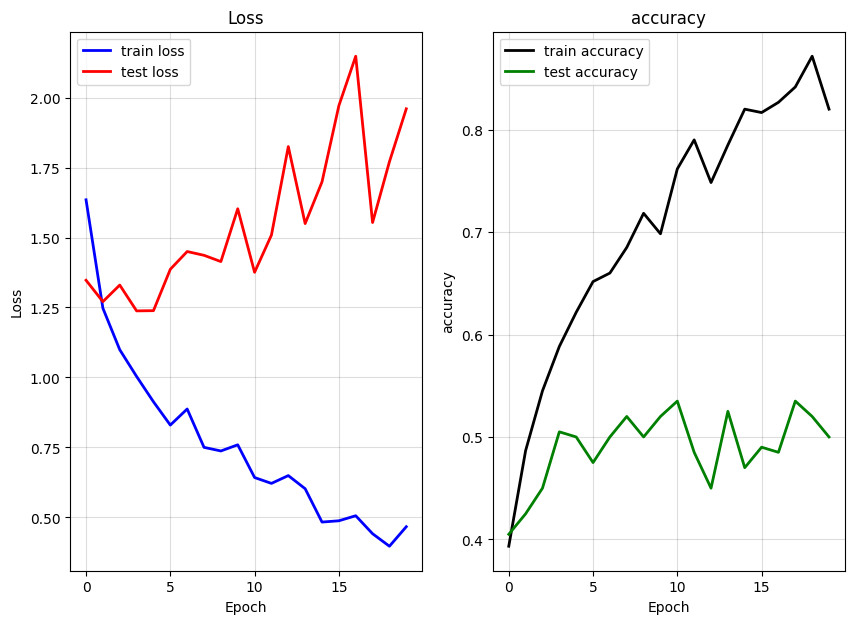

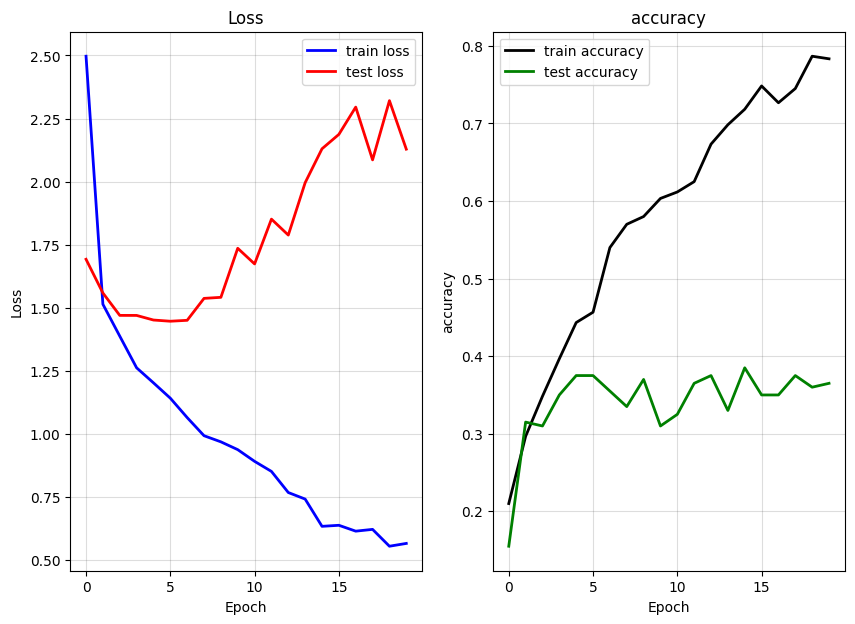

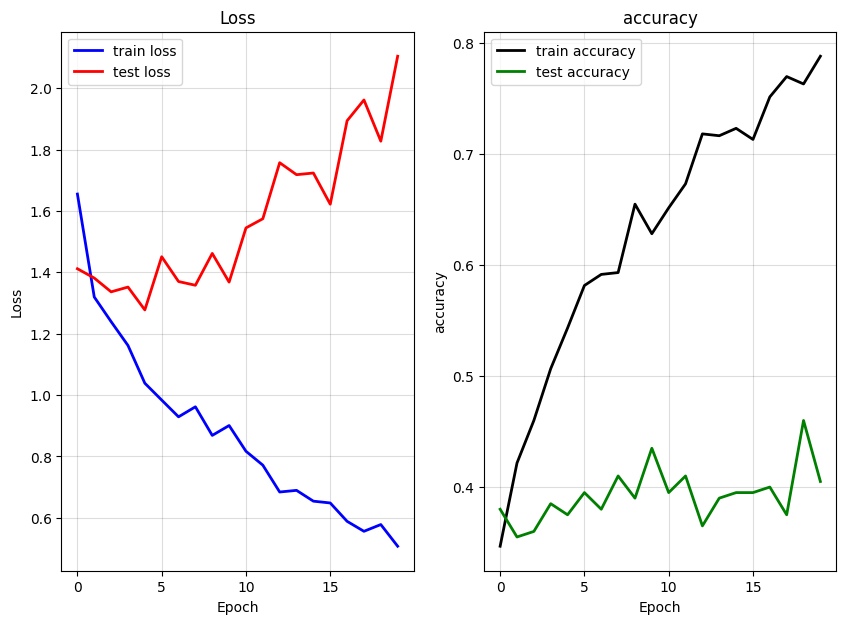

In [8]:
for config in Configuration.all():
    fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(10,7))
    axes[0].plot(range(epochs), history_dict[config]['train_loss'] , color='blue', linewidth=2, label='train loss')
    if not train_only:
        axes[0].plot(range(epochs), history_dict[config]['test_loss'] , color='red', linewidth=2, label='test loss')
    axes[0].set_title(f'Loss')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Loss')
    axes[0].legend()
    axes[0].grid(True, alpha=0.2, color='#555')
    axes[1].plot(range(epochs), history_dict[config]['train_accuracy'],color="black",linewidth=2, label=f'train accuracy')
    if not train_only:
        axes[1].plot(range(epochs), history_dict[config]['test_accuracy'],color="green",linewidth=2, label=f'test accuracy')
    axes[1].set_title(f'accuracy')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('accuracy')
    axes[1].legend()
    axes[1].grid(True, alpha=0.2, color='#555')

    gnn_curves_path = output_path/"metric_curves"/"gnn"/f"{config}_loss_accuracy.png"
    plt.savefig(gnn_curves_path)
    print(f"\n[OK] {config} curves saved to {gnn_curves_path}")

